# Efecto del aumento de datos en ConvNeXt-Tiny

## Pregunta

¿Cuánto cambian la detección y la clasificación por estadio al añadir el aumento histórico de escala y fotometría durante el entrenamiento?

| Hallazgo en el notebook de Andrés | Decisión | Comprobación |
| --- | --- | --- |
| Grupos MD5 y coseno ≥ 0,96 dieron 762 representantes | Usar la misma reconstrucción y curación que en el notebook 1 | Conteos, exclusiones y revisión de cruces |
| Diferencias por clase en RGB y relleno | Medir cómo altera esas señales el aumento | Variantes de la misma imagen y contrastes dentro de fuente |
| Andrés ya usaba recorte, giro, espejo y ajuste de color | Tratar su receta como una corrida histórica aparte | Factorial Base × Malignant con inicialización ImageNet |
| Ganador calibrado en validación | Seleccionar épocas y umbrales solo en validación | Curvas, matrices y diferencias pareadas |

Referencias locales [Comprobación del mejor modelo](../Andres_Arbelaez/Comprobacion_mejor_modelo.ipynb) y [script histórico 11](codigos_y_scripts/11_estudio_2_vs_3_clases_y_data_augmentation.py). Este notebook ejecuta su propio protocolo y conserva una copia de la lógica de partición y evaluación.

**Ejecución registrada.** Piloto completo con los cuatro brazos y una época de ajuste por brazo. Debajo se guardan las salidas de los cuatro brazos de 20 épocas de ajuste sobre todos los elegibles.

## Configuración

Ejecuta desde la raíz del repositorio o desde `Fabian/`. El modo predeterminado es piloto. Define `FABIAN_MODO=completo` antes de iniciar Jupyter para usar todos los datos elegibles. Puedes cambiar `FABIAN_REPO`, `FABIAN_SALIDA`, `FABIAN_SPLITS_ANDRES` y `FABIAN_CHECKPOINT_ANDRES`. `FABIAN_SHA256_ANDRES` admite una huella obtenida de la fuente del checkpoint. Las salidas de piloto y completo tienen carpetas propias en el directorio local de Fabián. Este bloque registra las versiones y crea esas carpetas.

In [1]:
%matplotlib inline
import ast
import hashlib
import json
import os
import platform
import random
import re
import sys
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from PIL import Image
from sklearn.model_selection import train_test_split

ROOT = Path(os.environ.get("FABIAN_REPO", Path.cwd())).resolve()
if ROOT.name == "Fabian":
    ROOT = ROOT.parent
assert (ROOT / "Andres_Arbelaez/Comprobacion_mejor_modelo.ipynb").is_file(), "Configura FABIAN_REPO con la raíz"
HIST = ROOT / "Fabian/resultados_y_datos/caracteristicas_retinografias"
SCRIPTS = ROOT / "Fabian/codigos_y_scripts"
OUTPUT = Path(os.environ.get("FABIAN_SALIDA", Path(os.environ.get("LOCALAPPDATA", Path.home() / ".cache")) / "glaucoma-fabian"))
PILOT = os.environ.get("FABIAN_MODO", "piloto") != "completo"
SEED = 42
RUN = OUTPUT / ("piloto" if PILOT else "completo")
AUDIT = OUTPUT / "auditoria"
AUDIT.mkdir(parents=True, exist_ok=True)
RUN.mkdir(parents=True, exist_ok=True)
MANIFEST = Path(os.environ.get("FABIAN_SPLITS_ANDRES", ROOT / "Andres_Arbelaez/resultados_y_datos/splits_moondream.csv"))
CHECKPOINT = Path(os.environ.get("FABIAN_CHECKPOINT_ANDRES", ROOT / "modelos/convnext_tiny_final.pth"))
CHECKPOINT_SHA = os.environ.get("FABIAN_SHA256_ANDRES", "").lower().strip()
MOON = "Moondream Staged"
CLASSES = ["Sano", "Etapa inicial", "Avanzado"]
BINARY = ["Sano", "Positivo"]
ENC = {"normal": 0, "early": 1, "advanced": 2}
COLORS = ["#137b80", "#c28616", "#8c3265"]
SOURCE_COLORS = ["#4069a0", "#bd7144", "#498574", "#89659a", "#9b842b"]
print(f"Modo {'piloto' if PILOT else 'completo'} · semilla {SEED} · salidas {RUN}")
print("Python", platform.python_version(), "|", {p: version(p) for p in ("numpy", "pandas", "Pillow", "scikit-learn", "matplotlib")})

def image_rgb(path):
    with Image.open(ROOT / path) as image:
        return image.convert("RGB")

def digest(path, algorithm="sha256"):
    with (ROOT / path).open("rb") as stream:
        return hashlib.file_digest(stream, algorithm).hexdigest()

def read_history(name):
    path = HIST / f"{name}.csv"
    return pd.read_csv(path, low_memory=False) if path.is_file() else pd.DataFrame()

def percentile_table(data, group, metrics):
    out = data.melt(id_vars=group, value_vars=list(metrics), var_name="medida", value_name="valor")
    out = out.groupby(group + ["medida"], dropna=False, sort=False)["valor"].agg(
        n="size", válidos="count", p25=lambda s: s.quantile(.25), mediana="median",
        p75=lambda s: s.quantile(.75)).reset_index()
    out["faltantes"] = out.n - out.válidos
    out["RIC"] = out.p75 - out.p25
    return out

def stratified_sample(data, keys, limit):
    if data.empty:
        return data.copy()
    groups = data.groupby(keys, dropna=False, sort=False)
    return pd.concat([g.sample(n=min(limit, len(g)), random_state=SEED) for _, g in groups]).sort_index()

Modo completo · semilla 42 · salidas C:\Users\fabi2\AppData\Local\glaucoma-fabian\completo
Python 3.14.2 | {'numpy': '2.4.0', 'pandas': '2.3.3', 'Pillow': '12.0.0', 'scikit-learn': '1.9.1', 'matplotlib': '3.10.8'}


## Datos y auditoría

### Reconstrucción de la partición de Andrés

Se indexan `train`, luego `test`, en el orden `normal`, `early`, `advanced`, con rutas ordenadas en cada clase. ResNet-18 con pesos ImageNet de torchvision y sin cabeza produce vectores normalizados L2. Su entrada es RGB, redimensionada a 224 × 224 con interpolación bilineal y normalizada con media y DE de ImageNet. Se ensayan cosenos 0,99/0,98/0,97/0,96 y se aplican **0,96 y MD5 idéntico** en un cierre transitivo. Se elimina por completo cada grupo con etiquetas contradictorias. En los demás se conserva el primer archivo en el orden de entrada. La división estratificada reserva 15 % para test y 17,65 % del resto para validación. Ambas llamadas usan semilla 42. El manifiesto publicado, cuando está disponible, se compara por ruta relativa, etiqueta, partición y orden. Hasta entonces, el resultado de este bloque se denomina **reconstrucción sin confirmar**.

In [2]:
import torch
import torchvision
from torchvision import transforms as T
from torchvision.models import ConvNeXt_Tiny_Weights, ResNet18_Weights, convnext_tiny, resnet18

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
torch.set_num_threads(min(6, os.cpu_count() or 1))
MEAN, STD = [.485, .456, .406], [.229, .224, .225]
EVAL_PIL = T.Resize((224, 224))
TO_MODEL = T.Compose([T.ToTensor(), T.Normalize(MEAN, STD)])
TF_EVAL = T.Compose([EVAL_PIL, TO_MODEL])
MOON_DIR = ROOT / "data/MOONDREAM_STAGED"
EXPECTED = pd.DataFrame([[274, 127, 131], [59, 27, 29], [59, 27, 29]],
                        index=["train", "val", "test"], columns=list(ENC))
print("PyTorch", torch.__version__, "| torchvision", torchvision.__version__, "| dispositivo", DEVICE)

class Components:
    def __init__(self, keys):
        self.parent = {key: key for key in keys}

    def find(self, key):
        while self.parent[key] != key:
            self.parent[key] = self.parent[self.parent[key]]
            key = self.parent[key]
        return key

    def link(self, a, b):
        self.parent[self.find(a)] = self.find(b)

def moon_pool():
    rows = []
    for split in ("train", "test"):
        for label in ENC:
            for path in sorted((MOON_DIR / split / label).rglob("*")):
                if path.is_file() and path.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}:
                    relative = path.relative_to(ROOT).as_posix()
                    rows.append({"id": relative, "original": split, "clase": label, "md5": digest(relative, "md5")})
    return pd.DataFrame(rows, columns=["id", "original", "clase", "md5"])

def scenario_signature(rows):
    return hashlib.sha256(rows.to_csv(index=False).encode("utf-8")).hexdigest()

def reconstruct(pool):
    weights = ResNet18_Weights.DEFAULT
    signature = scenario_signature(pool)
    cache = AUDIT / f"resnet18_{signature[:16]}_{DEVICE}_{torch.__version__.split('+')[0]}_{torchvision.__version__.split('+')[0]}.npz"
    if cache.is_file():
        embeddings = np.load(cache)["embeddings"]
    else:
        model = resnet18(weights=weights)
        model.fc = torch.nn.Identity()
        model = model.eval().to(DEVICE)
        blocks = []
        with torch.inference_mode():
            for start in range(0, len(pool), 64):
                batch = torch.stack([TF_EVAL(image_rgb(p)) for p in pool.id.iloc[start:start + 64]])
                blocks.append(torch.nn.functional.normalize(model(batch.to(DEVICE)), dim=1).cpu())
        embeddings = torch.cat(blocks).numpy()
        with cache.with_suffix(".tmp").open("wb") as stream:
            np.savez_compressed(stream, embeddings=embeddings)
        cache.with_suffix(".tmp").replace(cache)
        del model
    vectors = torch.from_numpy(embeddings)
    similarity = (vectors @ vectors.T).numpy()
    component = Components(pool.id)
    sensitivity = []
    original = pool.original.to_numpy()
    ids = pool.id.to_numpy()
    for threshold in (.99, .98, .97, .96):
        a, b = np.where(np.triu(similarity >= threshold, 1))
        sensitivity.append([threshold, len(a), int((original[a] != original[b]).sum())])
        if threshold == .96:
            for left, right in zip(ids[a], ids[b]):
                component.link(left, right)
            cosine_pairs = pd.DataFrame({"a": ids[a], "b": ids[b], "coseno": similarity[a, b]})
    for _, group in pool.groupby("md5"):
        for key in group.id.iloc[1:]:
            component.link(group.id.iloc[0], key)
    grouped = pool.assign(grupo=pool.id.map(component.find))
    conflicts = grouped.groupby("grupo").clase.nunique().loc[lambda s: s > 1].index
    valid = grouped.loc[~grouped.grupo.isin(conflicts)]
    clean = valid.drop_duplicates("grupo")
    trainval, test = train_test_split(clean, test_size=.15, stratify=clean.clase, random_state=42)
    train, val = train_test_split(trainval, test_size=.1765, stratify=trainval.clase, random_state=42)
    new = pd.concat([g[["id", "clase"]].assign(split=label)
                     for g, label in ((train, "train"), (val, "val"), (test, "test"))], ignore_index=True)
    info = pd.DataFrame(sensitivity, columns=["umbral", "pares", "cruces train/test originales"])
    print(f"Grupos MD5 que cruzan el split original: {pool.groupby('md5').original.nunique().gt(1).sum()}")
    print(f"Archivos originales: {len(pool)} · sin conflicto: {len(valid)} · representantes: {len(clean)} · grupos con conflicto: {len(conflicts)}")
    display(info)
    grouped.to_csv(AUDIT / "grupos_andres_reconstruidos.csv", index=False)
    return new, cosine_pairs

def normalize_moon_path(value):
    normalized = str(value).replace(chr(92), "/")
    marker = "MOONDREAM_STAGED/"
    assert marker in normalized, f"Ruta ajena a Moondream: {normalized}"
    return "data/" + normalized[normalized.index(marker):]

def counts(table):
    return pd.crosstab(table.split, table.clase).reindex(index=EXPECTED.index, columns=EXPECTED.columns, fill_value=0)

POOL = moon_pool()
REF = pd.DataFrame(columns=["id", "clase", "split"])
COSINE = pd.DataFrame(columns=["a", "b", "coseno"])
REF_STATUS = "Sin datos locales suficientes"
REF_CONFIRMED = False
if not POOL.empty and POOL.groupby("clase").size().min() >= 12 and POOL.clase.nunique() == 3:
    REBUILT, COSINE = reconstruct(POOL)
    REBUILT.to_csv(AUDIT / "splits_moondream_reconstruido.csv", index=False)
    REF, REF_STATUS = REBUILT, "Reconstrucción sin confirmar"
    if MANIFEST.is_file():
        published = pd.read_csv(MANIFEST, encoding="utf-8-sig")
        published = published.assign(id=published.ruta.map(normalize_moon_path))[["id", "clase", "split"]]
        assert published.id.is_unique, "Rutas repetidas en el manifiesto de Andrés"
        assert published.clase.eq(published.id.map(POOL.set_index("id").clase)).all(), "Rutas o etiquetas del manifiesto inválidas"
        assert counts(published).equals(EXPECTED) and len(published) == 762, "Conteos del manifiesto distintos de la bitácora"
        diff = published.merge(REBUILT, on=["id", "clase", "split"], how="outer", indicator=True)
        display(diff["_merge"].value_counts().rename("rutas y etiquetas por split"))
        print("Mismo orden de filas:", published.reset_index(drop=True).equals(REBUILT))
        REF, REF_STATUS, REF_CONFIRMED = published, "Manifiesto de Andrés aportado y comprobado contra los archivos locales", True
    else:
        print(f"Manifiesto publicado ausente: {MANIFEST}. Los conteos carecen de evidencia de identidad por ruta.")
    display(pd.concat({"Disponible": counts(REF), "Publicado": EXPECTED}, axis=1))
print(REF_STATUS)
assert REF.empty or REF.id.is_unique

PyTorch 2.14.1+cu126 | torchvision 0.29.1+cu126 | dispositivo cuda


Grupos MD5 que cruzan el split original: 12
Archivos originales: 800 · sin conflicto: 800 · representantes: 762 · grupos con conflicto: 0


,umbral,pares,cruces train/test originales
0,0.99,34,12
1,0.98,34,12
2,0.97,35,12
3,0.96,38,13


Manifiesto publicado ausente: C:\Users\fabi2\OneDrive\Escritorio\ProyectoDL-Grupo2-Glaucoma\Andres_Arbelaez\resultados_y_datos\splits_moondream.csv. Los conteos carecen de evidencia de identidad por ruta.


Disponible                Publicado               
          normal early advanced    normal early advanced
train        274   127      131       274   127      131
val           59    27       29        59    27       29
test          59    27       29        59    27       29

Reconstrucción sin confirmar


### Cruces en la referencia y entre fuentes

Se comprueba SHA-256 contra el inventario de las cinco fuentes originales y se enlazan coincidencias exactas de píxeles, pares SIFT/RANSAC, coseno del protocolo de Andrés y originales/derivados de procedencia verificada en la corrida histórica. Los códigos r3 de RIM con lateralidad se agrupan de forma conservadora cuando comparten el prefijo numérico. Moondream y las demás colecciones carecen de un identificador de paciente verificable en los insumos usados. Los grupos sirven para proteger la evaluación frente a variantes visuales y su interpretación queda a nivel de archivo. La búsqueda geométrica histórica puede omitir espejados o recortes severos.

Se conserva la partición de referencia y se crea una vista elegible separada. Ante un cruce se mantiene el representante compatible con la prioridad train → validación → test. Así se protege el test frente a grupos vistos por un checkpoint que hubiese usado el train publicado. En una misma partición se conserva una ruta estable por grupo. Se excluyen los grupos con conflicto dentro de un esquema y las imágenes externas vinculadas con cualquier archivo del pool Moondream. Los derivados enlazan sus fuentes y quedan fuera del denominador externo. Se registran las exclusiones por ruta, incluidos los motivos, y se tabulan cohortes con sus denominadores.

En Moondream, «Glaucoma» en la cabeza de Andrés significa **Avanzado**. En ACRIMA y RIM-ONE DL significa **positivo binario** según su fuente. En EyePACS REAL se usan las clases de cribado locales RG/NRG. Se optó por mantener incluso los sanos de referencia binaria fuera de la fila Sano trinaria. Su aporte queda registrado en la fila Sano de cada evaluación binaria externa.

In [3]:
from collections import defaultdict

HROWS = read_history("por_imagen")
GEOMETRY = read_history("coincidencias_geometricas")
EXACT = read_history("duplicados")
COHORTS = ["ACRIMA", "RIM-ONE DL", "EyePACS REAL"]
INTERNAL = "Moondream · test"

def control_eligibility():
    if any(table.empty for table in (HROWS, GEOMETRY, EXACT)):
        print("Auditoría de cruces pendiente: faltan por_imagen.csv o las tablas históricas de coincidencias.")
        return pd.DataFrame(), pd.DataFrame(), pd.DataFrame()
    assert HROWS.id_imagen.is_unique
    primary = HROWS.loc[HROWS.coleccion.isin([MOON, *COHORTS, "EyePACS TRAIN"])].copy()
    primary["verificado"] = [
        (ROOT / p).is_file() and digest(p) == sha
        for p, sha in primary[["id_imagen", "sha256_archivo"]].itertuples(index=False, name=None)
    ]
    print(f"Rutas SHA-256 vigentes: {primary.verificado.sum()}/{len(primary)} en las cinco cohortes originales.")
    moon_valid = set(primary.loc[primary.coleccion.eq(MOON) & primary.verificado, "id_imagen"])
    if not set(REF.id).issubset(moon_valid):
        print("Cobertura incompleta en la auditoría de Moondream. Se suspende la evaluación hasta actualizar el inventario.")
        return pd.DataFrame(), pd.DataFrame(), pd.DataFrame()

    graph = Components(HROWS.id_imagen)
    edges = []

    def link(a, b, evidence):
        if a != b and a in graph.parent and b in graph.parent:
            graph.link(a, b)
            edges.append((a, b, evidence))

    for _, rows in EXACT.groupby("sha256_pixeles"):
        for path in rows.id_imagen.iloc[1:]:
            link(rows.id_imagen.iloc[0], path, "píxeles idénticos")
    for a, b in GEOMETRY[["id_a", "id_b"]].itertuples(index=False, name=None):
        link(a, b, "SIFT/RANSAC histórico")
    for a, b in HROWS.loc[HROWS.estado_par.isin(["verificado_bytes", "verificado_pixeles_aproximados"]),
                          ["id_imagen", "id_original"]].itertuples(index=False, name=None):
        link(a, b, "derivado de origen verificado en la corrida histórica")
    for a, b, cosine in COSINE.itertuples(index=False, name=None):
        link(a, b, f"coseno ResNet-18 {cosine:.3f}")
    for _, rows in POOL.groupby("md5"):
        for key in rows.id.iloc[1:]:
            link(rows.id.iloc[0], key, "MD5 idéntico")
    rim = primary.loc[primary.coleccion.eq("RIM-ONE DL")].copy()
    rim["identificador_candidato"] = rim.archivo.str.extract(r"^(r3_[A-Z]-\d+)-[LR]_")[0]
    for _, rows in rim.dropna(subset=["identificador_candidato"]).groupby("identificador_candidato"):
        for path in rows.id_imagen.iloc[1:]:
            link(rows.id_imagen.iloc[0], path, "código r3 compartido (agrupación conservadora)")

    reference = REF.assign(coleccion=MOON, grupo=REF.id.map(graph.find), verificado=True)
    external = primary.loc[primary.coleccion.isin(COHORTS), ["id_imagen", "coleccion", "etiqueta", "verificado"]]
    external = external.rename(columns={"id_imagen": "id", "etiqueta": "clase"}).assign(split="externo")
    external["grupo"] = external.id.map(graph.find)
    work = pd.concat([reference, external], ignore_index=True)
    original_labels = POOL.assign(grupo=POOL.id.map(graph.find))
    moon_groups = set(original_labels.grupo)
    conflict_moon = set(original_labels.groupby("grupo").clase.nunique().loc[lambda s: s > 1].index)
    bad_external = external.groupby(["grupo", "coleccion"]).clase.nunique().loc[lambda s: s > 1].index
    work["estado"] = "elegible"
    work.loc[~work.verificado, "estado"] = "archivo ausente o SHA-256 distinto"
    work.loc[work.coleccion.eq(MOON) & work.grupo.isin(conflict_moon), "estado"] = "grupo Moondream con etiquetas contradictorias"
    work.loc[work.split.eq("externo") & ~work.clase.isin(["normal", "glaucoma"]), "estado"] = "referencia binaria ausente"
    work.loc[work.split.eq("externo") & work.grupo.isin(moon_groups), "estado"] = "vínculo con el pool original Moondream"
    for group, source in bad_external:
        work.loc[work.grupo.eq(group) & work.coleccion.eq(source), "estado"] = "conflicto binario dentro de la fuente"
    grouped = work.loc[work.estado.eq("elegible")].groupby("grupo", sort=False)
    priority = {"train": 0, "val": 1, "test": 2, "externo": 3}
    source_order = {source: index for index, source in enumerate([MOON, *COHORTS])}
    for _, rows in grouped:
        ordered = rows.assign(prioridad=rows.split.map(priority), fuente=rows.coleccion.map(source_order))
        ordered = ordered.sort_values(["prioridad", "fuente", "id"])
        first = ordered.iloc[0]
        for item in ordered.iloc[1:].itertuples():
            work.loc[item.Index, "estado"] = (
                f"grupo compartido con {first.split}" if first.split != item.split else "otro representante del grupo"
            )
    pairs = pd.DataFrame(edges, columns=["a", "b", "evidencia"])
    reference_role = reference.set_index("id").split
    roles = work.set_index("id").split
    sources = HROWS.set_index("id_imagen").coleccion
    pairs["split_a"], pairs["split_b"] = pairs.a.map(roles), pairs.b.map(roles)
    pairs["fuente_a"], pairs["fuente_b"] = pairs.a.map(sources), pairs.b.map(sources)
    direct = pairs.loc[(pairs.split_a.notna() & pairs.split_b.notna() & pairs.split_a.ne(pairs.split_b))
                       | pairs.fuente_a.ne(pairs.fuente_b)]
    detail = work.groupby(["coleccion", "split", "estado"], sort=False).size().rename("n").reset_index()
    reference_links = reference.groupby("grupo").split.nunique().gt(1)
    print(f"Componentes de la referencia con cruce train/val/test: {reference_links.sum()}.")
    print(f"Enlaces directos interpartición/interfuente: {len(direct)} (incluyen derivados).")
    display(detail)
    work.to_csv(AUDIT / "elegibilidad_por_imagen.csv", index=False)
    direct.to_csv(AUDIT / "enlaces_interparticion_o_fuente.csv", index=False)
    keep = work.loc[work.estado.eq("elegible")].copy()
    assert keep.grupo.is_unique
    keep["y3"] = keep.clase.map(ENC).where(keep.coleccion.eq(MOON))
    keep["y2"] = keep.clase.ne("normal").astype(int)
    return keep, direct, work

ELIGIBLE, LINKS, DECISIONS = control_eligibility()
catalog = [
    [MOON, "MOONDREAM_STAGED · copia local", "Carpetas + split de Andrés/reconstrucción", "70/15/15 de referencia", "Trinaria local", "normal / early / advanced", "Entrenamiento, validación, detección y estadio interno"],
    ["ACRIMA", "Database/Images · recortes", "Database/Readme.txt + nombres", "Externa, sin split oficial local", "Binaria anotada", "normal / glaucoma", "Detección externa"],
    ["RIM-ONE DL", "RIM_ONE_DL · recortes", "metadata.csv · etiqueta por ruta", "Externa, sin split oficial local", "Binaria del manifiesto", "normal / glaucoma", "Detección externa; incluye la clasificación local de serie S"],
    ["EyePACS REAL", "EYEPACS_REAL · muestras RG/NRG", "Carpetas + nombres RG/NRG", "Prueba externa del proyecto", "Binaria local de cribado", "normal / glaucoma", "Detección exploratoria según referencia RG/NRG"],
    ["EyePACS TRAIN", "EYEPACS_TRAIN · serie BEH", "Carpetas", "Entrenamiento del proyecto", "Binaria de carpeta", "normal / glaucoma", "Descripción y auditoría; fuera del entrenamiento de este estudio"],
    ["Megacohorte", "HARMONIZED_MEGA_COHORT · derivados", "results/harmonized_mega_cohort_index.csv", "train/test históricos", "Binaria recodificada", "normal / glaucoma", "Auditoría de procedencia y análisis de transformaciones"],
    ["THIRD_DATASET", "THIRD_DATASET · mapas RGBA", "Carpetas", "Sin partición verificable", "Binaria de carpeta; origen incierto", "non_glaucoma / glaucoma", "Descripción del archivo"],
    ["Web emulada", "WEB_IN_THE_WILD · derivados y distractores", "Pares comprobados con ACRIMA", "raw/filtered/rejected", "Origen binario parcial; derivados", "normal en pares de ACRIMA", "Descripción y comparación de procesamiento"],
    ["Google de Andrés", "Drive privado · lote de 588 reportado", "manifiesto.csv de limpieza, ausente", "Colección exploratoria", "Sin referencia verificada", "Sin etiquetas supervisadas", "Exploración sin métricas de clasificación"],
]
TABLE = pd.DataFrame(catalog, columns=["Fuente", "Versión local", "Manifiesto", "Partición", "Nivel", "Clases", "Uso"])
if not HROWS.empty:
    TABLE["n inventario histórico"] = TABLE.Fuente.map(HROWS.coleccion.value_counts()).fillna(0).astype(int)
if not ELIGIBLE.empty:
    TABLE["n elegible (todos los splits)"] = TABLE.Fuente.map(ELIGIBLE.coleccion.value_counts()).fillna(0).astype(int)
display(TABLE)

Rutas SHA-256 vigentes: 2352/2352 en las cinco cohortes originales.


Componentes de la referencia con cruce train/val/test: 25.
Enlaces directos interpartición/interfuente: 3044 (incluyen derivados).


,coleccion,split,estado,n
0,Moondream Staged,train,elegible,504
1,Moondream Staged,train,otro representante del grupo,28
2,Moondream Staged,val,elegible,107
3,Moondream Staged,val,grupo compartido con train,8
4,Moondream Staged,test,elegible,95
5,Moondream Staged,test,grupo compartido con train,10
6,Moondream Staged,test,otro representante del grupo,2
7,Moondream Staged,test,grupo compartido con val,8
8,ACRIMA,externo,elegible,703
9,ACRIMA,externo,otro representante del grupo,2


,Fuente,Versión local,Manifiesto,Partición,Nivel,Clases,Uso,n inventario histórico,n elegible (todos los splits)
0,Moondream Staged,MOONDREAM_STAGED · copia local,Carpetas + split de Andrés/reconstrucción,70/15/15 de referencia,Trinaria local,normal / early / advanced,"Entrenamiento, validación, detección y estadio...",800,706
1,ACRIMA,Database/Images · recortes,Database/Readme.txt + nombres,"Externa, sin split oficial local",Binaria anotada,normal / glaucoma,Detección externa,705,703
2,RIM-ONE DL,RIM_ONE_DL · recortes,metadata.csv · etiqueta por ruta,"Externa, sin split oficial local",Binaria del manifiesto,normal / glaucoma,Detección externa; incluye la clasificación lo...,447,447
3,EyePACS REAL,EYEPACS_REAL · muestras RG/NRG,Carpetas + nombres RG/NRG,Prueba externa del proyecto,Binaria local de cribado,normal / glaucoma,Detección exploratoria según referencia RG/NRG,200,200
4,EyePACS TRAIN,EYEPACS_TRAIN · serie BEH,Carpetas,Entrenamiento del proyecto,Binaria de carpeta,normal / glaucoma,Descripción y auditoría; fuera del entrenamien...,200,0
5,Megacohorte,HARMONIZED_MEGA_COHORT · derivados,results/harmonized_mega_cohort_index.csv,train/test históricos,Binaria recodificada,normal / glaucoma,Auditoría de procedencia y análisis de transfo...,2937,0
6,THIRD_DATASET,THIRD_DATASET · mapas RGBA,Carpetas,Sin partición verificable,Binaria de carpeta; origen incierto,non_glaucoma / glaucoma,Descripción del archivo,2805,0
7,Web emulada,WEB_IN_THE_WILD · derivados y distractores,Pares comprobados con ACRIMA,raw/filtered/rejected,Origen binario parcial; derivados,normal en pares de ACRIMA,Descripción y comparación de procesamiento,148,0
8,Google de Andrés,Drive privado · lote de 588 reportado,"manifiesto.csv de limpieza, ausente",Colección exploratoria,Sin referencia verificada,Sin etiquetas supervisadas,Exploración sin métricas de clasificación,0,0


### Auditoría de esta ejecución

Los conteos del protocolo de Andrés coincidieron con su bitácora a los cuatro umbrales. En la reconstrucción local hubo **27 enlaces directos SIFT/RANSAC** entre train, validación y test, y **cero enlaces directos por MD5, píxeles idénticos o coseno ≥0,96** entre esas particiones. La unión transitiva marcó 25 componentes entre particiones. Se apartaron 28 archivos de train, 8 de validación y 20 de test. La vista de análisis quedó en **504/107/95**. Los vínculos directos entre fuentes del inventario enlazaron originales y derivados históricos. Los dos archivos externos descartados eran representantes adicionales de grupos ACRIMA.

## Método de entrenamiento

Cada modelo nuevo arranca con ConvNeXt-Tiny ImageNet de torchvision y una nueva cabeza lineal de 768 entradas. Se aplica entropía cruzada sin ponderar, AdamW (`weight_decay=1e-4`), una época a 0,001 con la cabeza entrenable y un ajuste global a 0,0001 con agenda coseno hasta 0,000001. El piloto toma hasta 16 ejemplos por estrato de clase, fuente y split y hace una época de ajuste con lotes de 16. El completo usa todos los elegibles, 20 épocas de ajuste y lotes de 32. Se restaura la mejor época por 0,5 × F1 macro + 0,5 × sensibilidad media de las clases positivas usando argmax en validación. Se fija la semilla antes de construir cada brazo. Se calibra luego el umbral con validación, usando primero el objetivo de 95 % de especificidad y, si ningún candidato lo alcanza, la mayor especificidad observada y el score para resolver empates. Los checkpoints de las corridas nuevas se guardan con una firma de la configuración y de las rutas de entrenamiento y validación.

In [4]:
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import functional as TF
from sklearn.metrics import (average_precision_score, cohen_kappa_score, confusion_matrix, f1_score,
                             precision_recall_curve, recall_score, roc_auc_score, roc_curve)

AUG_SCRIPT = SCRIPTS / "11_estudio_2_vs_3_clases_y_data_augmentation.py"
aug_source = AUG_SCRIPT.read_text(encoding="utf-8-sig")
aug_node = next(n for n in ast.parse(aug_source).body
                if isinstance(n, ast.ClassDef) and n.name == "MalignantScaleAugmentation")
# Carga la clase histórica sin ejecutar las escrituras ni el entrenamiento del script.
exec(compile(ast.Module(body=[aug_node], type_ignores=[]), str(AUG_SCRIPT), "exec"))
MALIGNANT_PIL = T.Compose([MalignantScaleAugmentation(output_size=(224, 224)),
                           T.RandomHorizontalFlip(), T.RandomVerticalFlip()])
ANDRES_PIL = T.Compose([T.RandomResizedCrop(224, scale=(.8, 1), ratio=(.95, 1.05)),
                        T.RandomHorizontalFlip(), T.RandomRotation(15),
                        T.ColorJitter(brightness=.2, contrast=.2, saturation=.2, hue=.03)])
RECIPES = {"Base": EVAL_PIL, "Malignant": MALIGNANT_PIL, "Receta Andrés": ANDRES_PIL}
BATCH = 16 if PILOT else 32
EPOCHS = 1 if PILOT else 20
WARM = 1
CAP = 16
TRAIN, VAL = pd.DataFrame(), pd.DataFrame()
EVAL_SETS = {}
if not ELIGIBLE.empty:
    selected = stratified_sample(ELIGIBLE, ["coleccion", "split", "clase"], CAP) if PILOT else ELIGIBLE
    TRAIN = selected.loc[selected.split.eq("train")].reset_index(drop=True)
    VAL = selected.loc[selected.split.eq("val")].reset_index(drop=True)
    EVAL_SETS = {INTERNAL: selected.loc[selected.split.eq("test")].reset_index(drop=True)}
    EVAL_SETS.update({source: selected.loc[selected.coleccion.eq(source)].reset_index(drop=True) for source in COHORTS})
    EVAL_SETS = {name: table for name, table in EVAL_SETS.items() if len(table)}
    display(selected.groupby(["coleccion", "split", "clase"]).size().rename("n de esta corrida").reset_index())

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if DEVICE == "cuda":
        torch.cuda.manual_seed_all(seed)

class Retinas(Dataset):
    def __init__(self, rows, n_classes, transform):
        self.ids = rows.id.tolist()
        self.y = rows[f"y{n_classes}"].astype(int).tolist()
        self.transform = transform

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, index):
        return self.transform(image_rgb(self.ids[index])), self.y[index]

def batches(rows, n_classes, transform=TF_EVAL, shuffle=False):
    return DataLoader(Retinas(rows, n_classes, transform), batch_size=BATCH, shuffle=shuffle,
                      pin_memory=DEVICE == "cuda", num_workers=0, generator=torch.Generator().manual_seed(SEED))

def to_device(model):
    return model.to(DEVICE, memory_format=torch.channels_last) if DEVICE == "cuda" else model.to(DEVICE)

def make_convnext(n_classes, pretrained=True):
    model = convnext_tiny(weights=ConvNeXt_Tiny_Weights.DEFAULT if pretrained else None)
    model.classifier[2] = nn.Linear(model.classifier[2].in_features, n_classes)
    return to_device(model)

def predict(model, loader, compute_loss=True):
    model.eval()
    logits, y_true = [], []
    with torch.inference_mode():
        for x, y in loader:
            with torch.autocast("cuda", enabled=DEVICE == "cuda"):
                logits.append(model(x.to(DEVICE, non_blocking=True)).float().cpu())
            y_true.append(y)
    raw, y_true = torch.cat(logits), torch.cat(y_true)
    loss = nn.functional.cross_entropy(raw, y_true).item() if compute_loss else None
    return loss, raw.softmax(1).numpy()

def train_epoch(model, loader, optimizer, scaler):
    model.train()
    total = 0.
    for x, y in loader:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast("cuda", enabled=DEVICE == "cuda"):
            loss = nn.functional.cross_entropy(model(x), y)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        total += loss.detach().item() * len(y)
    return total / len(loader.dataset)

def select_score(y, pred, n_classes, missing=0):
    labels = np.arange(n_classes)
    recalls = recall_score(y, pred, labels=labels, average=None, zero_division=missing)
    f1 = f1_score(y, pred, labels=labels, average="macro", zero_division=missing)
    return .5 * f1 + .5 * np.mean(recalls[1:])

def p_positive(prob):
    return prob[:, 1:].sum(axis=1)

def decide(prob, tau):
    return np.where(p_positive(prob) >= tau, 1 + prob[:, 1:].argmax(axis=1), 0)

def calibrate(y, prob, n_classes):
    rows = []
    for tau in np.round(np.arange(.30, .96, .01), 2):
        pred = decide(prob, tau)
        rows.append({"tau": tau, "especificidad": np.mean(pred[y == 0] == 0),
                     "score": select_score(y, pred, n_classes)})
    table = pd.DataFrame(rows)
    feasible = table.loc[table.especificidad.ge(.95)]
    if feasible.empty:
        feasible = table.loc[table.especificidad.eq(table.especificidad.max())]
    chosen = feasible.sort_values(["score", "tau"], ascending=[False, True]).iloc[0]
    return float(chosen.tau), float(chosen.especificidad)

def fit(n_classes, recipe):
    if TRAIN.empty or VAL.empty:
        return None
    keys = ["id", "clase", "grupo"]
    if any(df[f"y{n_classes}"].nunique() != n_classes for df in (TRAIN, VAL)):
        print(f"Faltan clases para {n_classes} × {recipe}")
        return None
    identity = pd.concat([TRAIN[keys], VAL[keys]], keys=["train", "val"]).reset_index(level=0)
    signature = hashlib.sha256(
        (scenario_signature(identity) + digest(AUG_SCRIPT) + str((n_classes, recipe, EPOCHS, BATCH, WARM, SEED,
          DEVICE, torch.__version__, torchvision.__version__, "protocolo-2026-11-23-v1"))).encode()
    ).hexdigest()[:16]
    target = RUN / f"convnext_{n_classes}_{recipe.lower().replace(' ', '_')}_{signature}.pth"
    train_loader = batches(TRAIN, n_classes, T.Compose([RECIPES[recipe], TO_MODEL]), shuffle=True)
    val_loader = batches(VAL, n_classes)
    y_val = VAL[f"y{n_classes}"].to_numpy().astype(int)
    seed_everything(SEED)
    model = make_convnext(n_classes, pretrained=not target.is_file())
    if target.is_file():
        saved = torch.load(target, map_location="cpu", weights_only=True)
        model.load_state_dict(saved["state_dict"], strict=True)
    else:
        for param in model.parameters():
            param.requires_grad_(False)
        head = model.classifier[2]
        for param in head.parameters():
            param.requires_grad_(True)
        scaler = torch.amp.GradScaler("cuda", enabled=DEVICE == "cuda")
        opt_head = torch.optim.AdamW(head.parameters(), lr=1e-3, weight_decay=1e-4)
        for _ in range(WARM):
            train_epoch(model, train_loader, opt_head, scaler)
        for param in model.parameters():
            param.requires_grad_(True)
        optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-6)
        best_score, best_state, best_epoch, history = -np.inf, None, 0, []
        for epoch in range(1, EPOCHS + 1):
            train_loss = train_epoch(model, train_loader, optimizer, scaler)
            scheduler.step()
            val_loss, prob = predict(model, val_loader)
            score = select_score(y_val, prob.argmax(1), n_classes)
            history.append({"epoca": epoch, "train": train_loss, "val": val_loss, "score": float(score)})
            if PILOT or epoch in (1, 5, 10, 15, EPOCHS):
                print(f"{n_classes} clases · {recipe} · época {epoch}/{EPOCHS} · train {train_loss:.3f} · val {val_loss:.3f}", flush=True)
            if score > best_score:
                best_score, best_epoch = score, epoch
                best_state = {key: tensor.detach().cpu().clone() for key, tensor in model.state_dict().items()}
        model.load_state_dict(best_state)
        saved = {"state_dict": best_state, "history": history, "epoca": best_epoch}
        torch.save(saved, target.with_suffix(".tmp"))
        target.with_suffix(".tmp").replace(target)
    _, probs = predict(model, val_loader)
    return {"model": model, "hist": pd.DataFrame(saved["history"]), "epoca": saved["epoca"],
            "val_prob": probs, "peso": target.name}

def evaluate_scenarios(model, n_classes):
    out = {}
    for source, rows in EVAL_SETS.items():
        reference_level = n_classes if source == INTERNAL else 2
        _, prob = predict(model, batches(rows, reference_level), compute_loss=False)
        out[source] = prob
    return out

,coleccion,split,clase,n de esta corrida
0,ACRIMA,externo,glaucoma,395
1,ACRIMA,externo,normal,308
2,EyePACS REAL,externo,glaucoma,100
3,EyePACS REAL,externo,normal,100
4,Moondream Staged,test,advanced,25
5,Moondream Staged,test,early,21
6,Moondream Staged,test,normal,49
7,Moondream Staged,train,advanced,125
8,Moondream Staged,train,early,115
9,Moondream Staged,train,normal,264


Se definen matrices por fila real y métricas con su soporte. La sensibilidad binaria agrupa las referencias positivas y en trinario se reporta también el recobrado de cada estadio. Los errores adyacentes incluyen sano↔inicial e inicial↔avanzado. QWK pondera cuadráticamente la distancia ordinal. El bootstrap remuestrea 2.000 veces el mismo representante de grupo para ambos modelos, estratifica por referencia y resume percentiles de la diferencia. Se aplica con un mínimo de 10 grupos en cada clase. Los intervalos reflejan la variación de la muestra fijada y el agrupamiento visual disponible.

In [5]:
def metrics(y, pred, n_classes):
    cm = confusion_matrix(y, pred, labels=np.arange(n_classes))
    rows, columns = cm.sum(1), cm.sum(0)
    rates = np.divide(cm.diagonal(), rows, out=np.full(len(rows), np.nan), where=rows > 0)
    stats = {"n": len(y), "F1 macro": f1_score(y, pred, labels=np.arange(n_classes), average="macro", zero_division=0),
             "exactitud": np.trace(cm) / len(y), "sensibilidad": cm[1:, 1:].sum() / rows[1:].sum() if rows[1:].sum() else np.nan,
             "especificidad": rates[0]}
    stats["TFP"], stats["TFN"] = 1 - stats["especificidad"], 1 - stats["sensibilidad"]
    if n_classes == 3:
        stats.update({"recall inicial": rates[1], "recall avanzado": rates[2],
                      "QWK": cohen_kappa_score(y, pred, labels=[0, 1, 2], weights="quadratic")
                      if len(np.unique(np.r_[y, pred])) > 1 else np.nan,
                      "errores adyacentes": cm[0, 1] + cm[1, 0] + cm[1, 2] + cm[2, 1],
                      "errores sano ↔ avanzado": cm[0, 2] + cm[2, 0],
                      "FN inicial": cm[1, 0], "FN avanzado": cm[2, 0]})
    else:
        stats.update({"FP": cm[0, 1], "FN": cm[1, 0]})
    return stats, cm

def matrix(ax, cm, labels, title):
    support = cm.sum(axis=1, keepdims=True)
    pct = np.divide(cm, support, out=np.zeros_like(cm, dtype=float), where=support != 0)
    ax.imshow(pct, vmin=0, vmax=1, cmap="Blues")
    for (i, j), n in np.ndenumerate(cm):
        label = f"{n}\n{pct[i, j]:.0%}" if support[i, 0] else f"{n}\n—"
        ax.text(j, i, label, ha="center", va="center", color="white" if pct[i, j] > .55 else "#17283d")
    ax.set_xticks(range(len(labels)), labels, rotation=15)
    ax.set_yticks(range(len(labels)), [f"{label} (n={n})" for label, n in zip(labels, support.ravel())])
    ax.set(xlabel="Predicción", ylabel="Referencia", title=f"{title}\nn={int(cm.sum())}")

def matrices(panel, labels, title=None):
    fig, axes = plt.subplots(1, len(panel), figsize=(4.8 * len(panel), 4.3), squeeze=False, layout="constrained")
    for ax, (name, cm) in zip(axes.ravel(), panel.items()):
        matrix(ax, cm, labels, name)
    if title:
        fig.suptitle(title)
    plt.show()

def summarize_binary(y, pred, score):
    out, cm = metrics(y, pred, 2)
    if len(np.unique(y)) == 2:
        out["AUROC"] = roc_auc_score(y, score)
        out["AP"] = average_precision_score(y, score)
    return out, cm

def binary_curves(rows, scores, source):
    y = rows.y2.to_numpy()
    if len(np.unique(y)) < 2:
        print(f"{source}: ROC y precisión–recobrado requieren ambas clases.")
        return
    fig, (a, b) = plt.subplots(1, 2, figsize=(10, 3.7), layout="constrained")
    for color, (name, score) in zip(SOURCE_COLORS, scores.items()):
        fpr, tpr, _ = roc_curve(y, score)
        precision, recall, _ = precision_recall_curve(y, score)
        a.plot(fpr, tpr, color=color, label=f"{name} · AUC {roc_auc_score(y, score):.3f}")
        b.plot(recall, precision, color=color, label=f"{name} · AP {average_precision_score(y, score):.3f}")
    a.plot([0, 1], [0, 1], "--", color="#707784")
    b.axhline(y.mean(), ls="--", color="#707784", label=f"Prevalencia {y.mean():.1%}")
    a.set(xlabel="TFP", ylabel="Sensibilidad", title="ROC")
    b.set(xlabel="Recobrado", ylabel="Precisión", title="Precisión–recobrado")
    for ax in (a, b):
        ax.legend(fontsize=8)
    fig.suptitle(f"{source} · n={len(rows)} · {y.sum()} positivos")
    plt.show()

def paired_delta(rows, y, before, after, n_classes, n_boot=2000):
    # La curación deja un representante por grupo. Se conserva ese mismo representante en ambos modelos.
    if rows.grupo.nunique() != len(rows) or np.bincount(y, minlength=n_classes).min() < 10:
        return pd.DataFrame()
    rng = np.random.default_rng(SEED)
    ix = np.concatenate([rng.choice(np.flatnonzero(y == c), (n_boot, (y == c).sum()), replace=True)
                         for c in range(n_classes)], axis=1)
    def estimates(pred, index):
        one_hot = np.eye(n_classes**2)[(y * n_classes + pred)[index]].sum(axis=1).reshape(-1, n_classes, n_classes)
        tp = np.diagonal(one_hot, axis1=1, axis2=2)
        f1 = np.mean(2 * tp / (one_hot.sum(1) + one_hot.sum(2)), axis=1)
        sensitivity = one_hot[:, 1:, 1:].sum((1, 2)) / one_hot[:, 1:, :].sum((1, 2))
        specificity = one_hot[:, 0, 0] / one_hot[:, 0, :].sum(1)
        return np.column_stack([f1, sensitivity, specificity])
    labels = ["F1 macro", "sensibilidad", "especificidad"]
    delta = (estimates(after, np.arange(len(y))[None]) - estimates(before, np.arange(len(y))[None]))[0]
    bands = np.percentile(estimates(after, ix) - estimates(before, ix), [2.5, 97.5], axis=0)
    return pd.DataFrame({"medida": labels, "delta": delta, "p2.5": bands[0], "p97.5": bands[1]})

def error_gallery(rows, y, pred, labels, source, limit=4):
    errors = rows.assign(y=y, pred=pred).loc[lambda d: d.y.ne(d.pred)]
    if errors.empty:
        return
    selected = stratified_sample(errors, ["y", "pred"], 1).head(limit)
    fig, axes = plt.subplots(1, len(selected), figsize=(3.1 * len(selected), 3.1), squeeze=False, layout="constrained")
    for ax, row in zip(axes.ravel(), selected.itertuples()):
        ax.imshow(image_rgb(row.id))
        ax.set_title(f"{labels[row.y]} → {labels[row.pred]}\n{Path(row.id).name}", color=COLORS[row.y], fontsize=9)
        ax.axis("off")
    fig.suptitle(f"{source} · {len(errors)} errores de {len(rows)}")
    plt.show()

def plot_links():
    if LINKS.empty:
        return
    review = LINKS.loc[LINKS.split_a.notna() & LINKS.split_b.notna() & LINKS.split_a.ne(LINKS.split_b)]
    review = review.loc[review.evidencia.str.contains("SIFT|coseno")].head(3)
    if review.empty:
        return
    fig, axs = plt.subplots(len(review), 2, figsize=(7, 2.4 * len(review)), squeeze=False, layout="constrained")
    for ax, row in zip(axs, review.itertuples()):
        for panel, path, split in zip(ax, (row.a, row.b), (row.split_a, row.split_b)):
            panel.imshow(image_rgb(path))
            panel.set_title(f"{split} · {Path(path).name}\n{row.evidencia}", fontsize=8)
            panel.axis("off")
    plt.show()

### Diseño y comprobación visual

El factorial cruza tarea de 2/3 clases con preprocesamiento Base y Malignant. Base aplica resize bilineal y normalización. Malignant usa el cuerpo de la clase del script 11 y conserva sus espejos horizontal y vertical. La clase aleja con probabilidad 0,45 (escala 0,25–0,65), con un lienzo ruidoso basado en el RGB medio y borde circular negro. Acerca con probabilidad 0,35 (1,25–1,85) mediante un recorte con desplazamiento, y deja la escala original en el 20 % restante. Aplica gamma y ganancia de verde con probabilidad 0,65. El tensor de evaluación siempre usa Base. El conjunto de entrenamiento se fija antes de transformar y conserva el identificador del archivo fuente. Ambas formulaciones comienzan con ImageNet y los brazos de una tarea tienen la misma inicialización, orden, presupuesto y criterio de selección.

La receta publicada de Andrés usa `RandomResizedCrop`, espejo horizontal, rotación y `ColorJitter`. Sus parámetros y operaciones definen una condición histórica distinta de los cuatro brazos. El notebook 1 ejecuta esa receta con los datos auditados.

In [6]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression

def full_image_color(image):
    pixels = np.asarray(image)
    corner_rgb = [block.reshape(-1, 3).mean(0) for block in (pixels[:4, :4], pixels[:4, -4:],
                                                             pixels[-4:, :4], pixels[-4:, -4:])]
    r, g, b = pixels.mean(axis=(0, 1))
    return {"R": r, "G": g, "B": b, "pad_negro": int(any(c.max() < 20 for c in corner_rgb)),
            "pad_gris": int(any(55 <= c.mean() <= 100 and np.ptp(c) < 8 for c in corner_rgb))}

def collect_color(rows):
    signals = pd.DataFrame([full_image_color(image_rgb(p)) for p in rows.id], index=rows.index)
    return pd.concat([rows, signals], axis=1)

Se generan variantes deterministas de originales de entrenamiento. El porcentaje conservado se mide sobre la máscara aproximada de retina visible del extractor histórico. Se calcula también RGB y relleno en pares Base/Malignant desglosados por clase y cohorte. Las transformaciones en fuentes externas que aparecen en esta figura son diagnósticas.

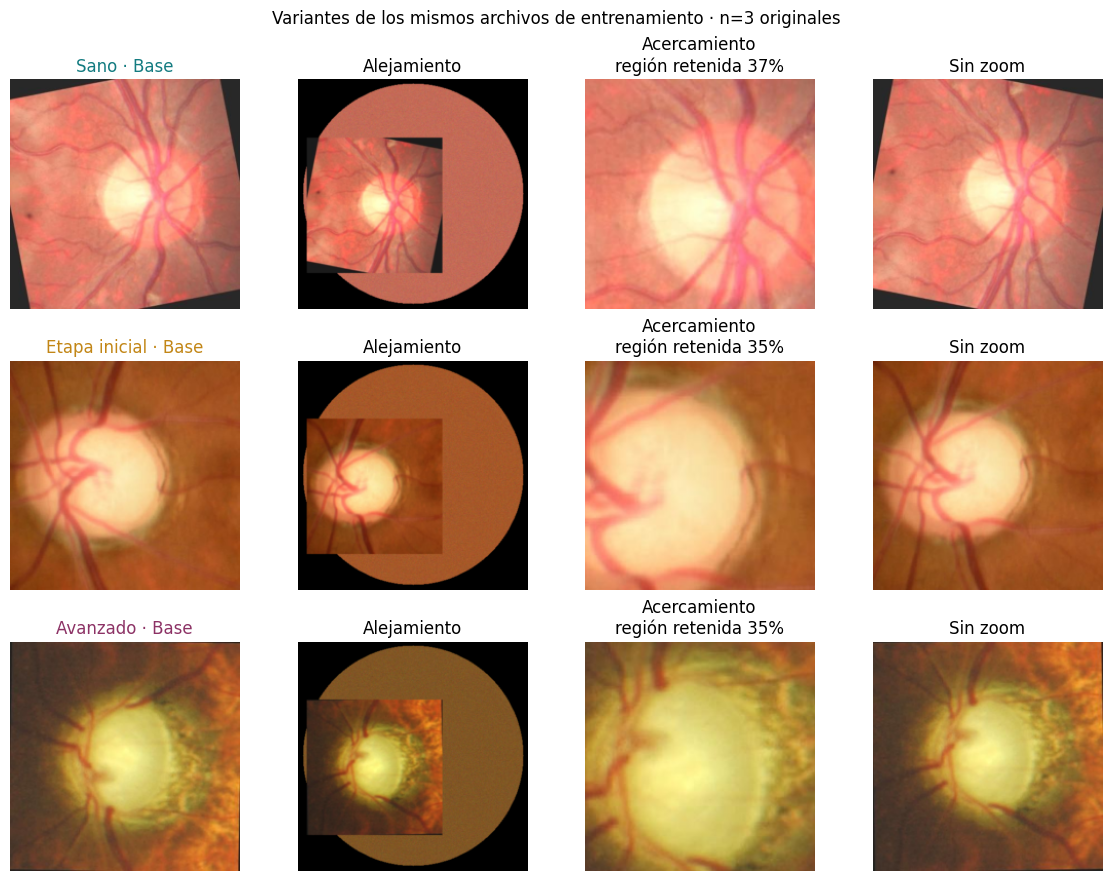

R       G      B  pad_negro  \
cohorte          clase    brazo                                         
ACRIMA           glaucoma Base       203.14   93.63  19.77       0.12   
                          Malignant  182.20   87.17  19.06       0.44   
                 normal   Base       172.77  100.94  26.61       0.14   
                          Malignant  157.63   93.07  25.77       0.48   
EyePACS REAL     glaucoma Base        87.91   57.55  39.75       1.00   
                          Malignant   79.74   51.24  34.01       0.90   
                 normal   Base        88.28   55.07  32.59       1.00   
                          Malignant   82.54   49.76  27.39       0.82   
Moondream Staged advanced Base       173.75  115.41  53.67       0.48   
                          Malignant  158.41  107.41  48.90       0.56   
                 early    Base       161.69  107.33  53.95       0.42   
                          Malignant  146.87   97.09  46.94       0.56   
                 normal   Base       161.05  108.17  74.36       0.52   
                          Malignant  147.15   98.03  66.22       0.56   
RIM-ONE DL       glaucoma Base       150.38   69.16  37.94       0.00   
                          Malignant  135.17   63.53  34.73       0.50   
                 normal   Base       148.15   64.10  33.49       0.00   
                          Malignant  137.50   59.21  29.51       0.46   

                                     pad_gris  casi_negro_pct  
cohorte          clase    brazo                                
ACRIMA           glaucoma Base           0.00            0.11  
                          Malignant      0.00           11.17  
                 normal   Base           0.00            0.09  
                          Malignant      0.00           12.16  
EyePACS REAL     glaucoma Base           0.00           25.04  
                          Malignant      0.00           23.70  
                 normal   Base           0.00           24.05  
                          Malignant      0.00           21.08  
Moondream Staged advanced Base           0.24            2.94  
                          Malignant      0.02           12.80  
                 early    Base           0.26            3.17  
                          Malignant      0.06           14.04  
                 normal   Base           0.14            4.15  
                          Malignant      0.04           14.17  
RIM-ONE DL       glaucoma Base           0.00            0.00  
                          Malignant      0.00           13.08  
                 normal   Base           0.00            0.00  
                          Malignant      0.00           12.08

,cohorte,clase,medida,n,válidos,p25,mediana,p75,faltantes,RIC
0,Moondream Staged,advanced,retención (%),18,18,35.90,43.26,48.68,0,12.78
1,Moondream Staged,early,retención (%),15,15,40.58,44.84,54.20,0,13.62
2,Moondream Staged,normal,retención (%),16,16,37.54,48.94,58.11,0,20.57
3,ACRIMA,normal,retención (%),21,21,35.39,46.39,51.75,0,16.36
4,ACRIMA,glaucoma,retención (%),17,17,36.53,45.46,48.30,0,11.77
5,RIM-ONE DL,glaucoma,retención (%),16,16,35.00,38.13,50.07,0,15.07
6,RIM-ONE DL,normal,retención (%),17,17,32.76,38.22,45.47,0,12.71
7,EyePACS REAL,glaucoma,retención (%),11,11,49.30,60.39,70.73,0,21.43
8,EyePACS REAL,normal,retención (%),14,14,44.92,52.91,61.16,0,16.24


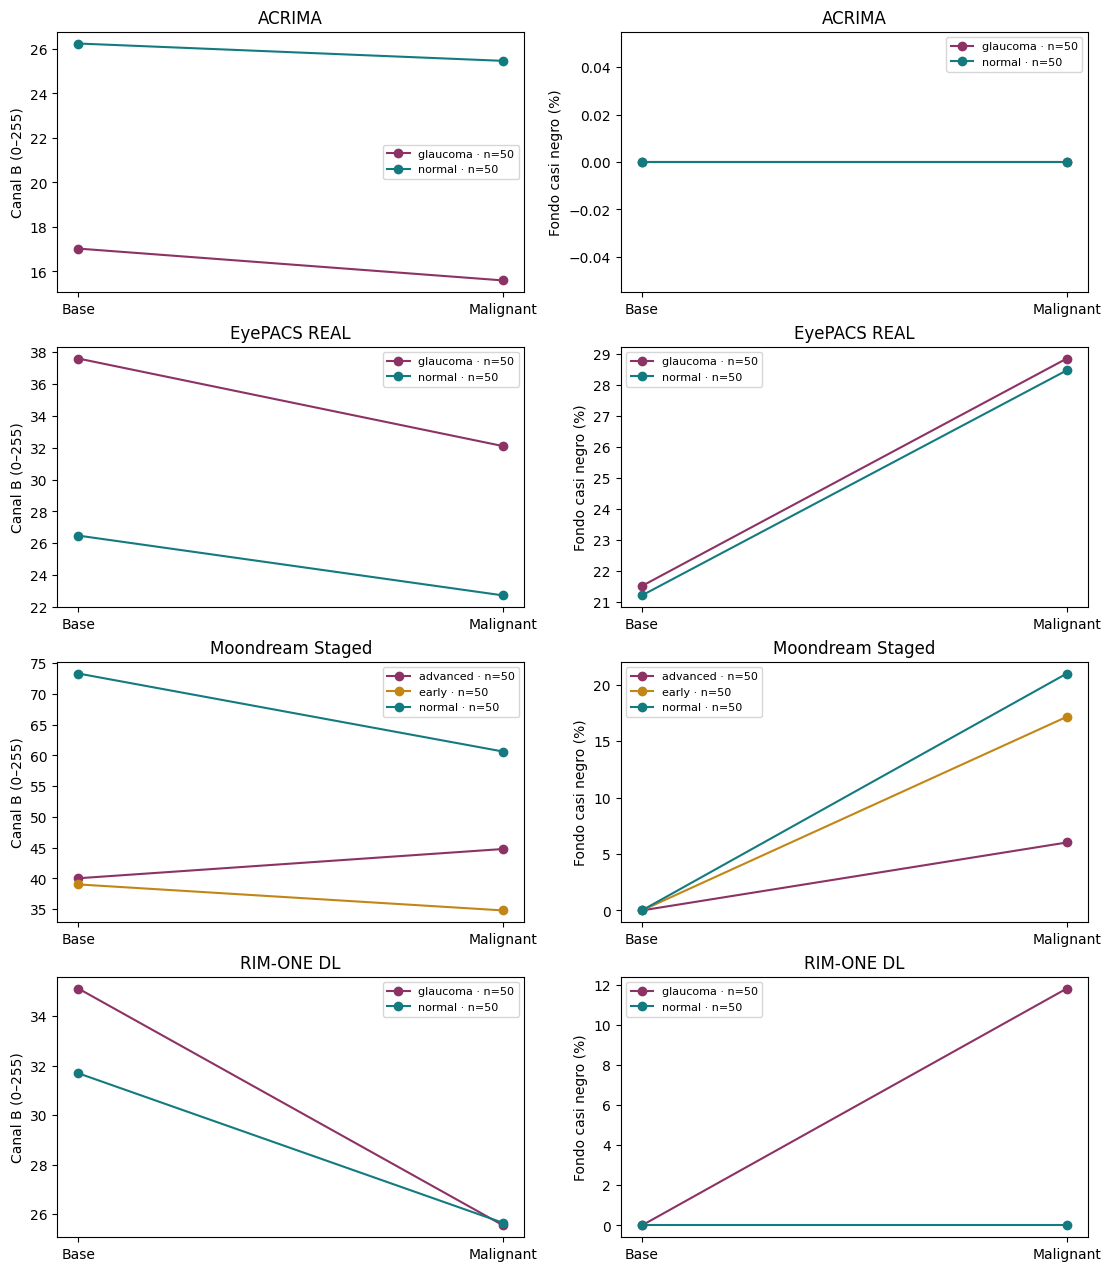

In [7]:
import cv2
sys.path.insert(0, str(SCRIPTS))
from metricas_retinografias import retinal_mask, thumbnail

def crop_window(seed, width, height):
    rng = random.Random(seed)
    roll = rng.random()
    if roll < .45:
        return "Alejamiento", None
    if roll >= .80:
        return "Sin zoom", None
    scale = rng.uniform(1.25, 1.85)
    w, h = int(width / scale), int(height / scale)
    dx, dy = width - w, height - h
    x = max(0, min(dx, int(dx // 2 + rng.uniform(-.15, .15) * dx)))
    y = max(0, min(dy, int(dy // 2 + rng.uniform(-.15, .15) * dy)))
    return "Acercamiento", (x, y, x + w, y + h)

def crop_retention(image, box):
    if box is None:
        return np.nan
    thumb = thumbnail(np.asarray(image))
    mask, category = retinal_mask(thumb)
    if category not in ("circular_visible", "rectangular_sin_contorno", "parcial_o_irregular"):
        return np.nan
    native = cv2.resize(mask.astype("uint8"), image.size, interpolation=cv2.INTER_NEAREST_EXACT)
    x0, y0, x1, y1 = box
    return 100 * native[y0:y1, x0:x1].sum() / native.sum() if native.any() else np.nan

if not TRAIN.empty:
    examples = stratified_sample(TRAIN, ["clase"], 1).sort_values("y3")
    fig, axes = plt.subplots(len(examples), 4, figsize=(11.5, 2.9 * len(examples)), squeeze=False, layout="constrained")
    for ax, row in zip(axes, examples.itertuples()):
        image = image_rgb(row.id)
        ax[0].imshow(EVAL_PIL(image))
        ax[0].set_title(f"{CLASSES[int(row.y3)]} · Base", color=COLORS[int(row.y3)])
        for panel, seed in zip(ax[1:], (1, 5, 2)):
            mode, box = crop_window(seed, *image.size)
            seed_everything(seed)
            panel.imshow(MALIGNANT_PIL(image))
            retained = crop_retention(image, box)
            panel.set_title(f"{mode}\nregión retenida {retained:.0f}%" if np.isfinite(retained) else mode)
        for panel in ax:
            panel.axis("off")
    fig.suptitle(f"Variantes de los mismos archivos de entrenamiento · n={len(examples)} originales")
    plt.show()

    condition_rows = pd.concat([TRAIN, *[df for name, df in EVAL_SETS.items() if name != INTERNAL]], ignore_index=True)
    condition_rows = stratified_sample(condition_rows, ["coleccion", "clase"], 12 if PILOT else 50)
    signals, crop_stats = [], []
    measure = ["R", "G", "B", "pad_negro", "pad_gris", "casi_negro_pct"]
    for i, row in enumerate(condition_rows.itertuples()):
        image = image_rgb(row.id)
        seed = SEED + i
        seed_everything(seed)
        variants = {"Base": EVAL_PIL(image), "Malignant": MALIGNANT_PIL(image)}
        for arm, variant in variants.items():
            black = 100 * (np.asarray(variant).max(2) <= 10).mean()
            signals.append({"id": row.id, "cohorte": row.coleccion, "clase": row.clase, "brazo": arm,
                            "casi_negro_pct": black, **full_image_color(variant)})
        mode, box = crop_window(seed, *image.size)
        if box:
            crop_stats.append({"cohorte": row.coleccion, "clase": row.clase, "id": row.id,
                               "retención (%)": crop_retention(image, box)})
    visual = pd.DataFrame(signals)
    visual.to_csv(RUN / "02_senales_visuales_pareadas.csv", index=False)
    tab = visual.groupby(["cohorte", "clase", "brazo"])[measure].mean().round(2)
    display(tab)
    if crop_stats:
        display(percentile_table(pd.DataFrame(crop_stats), ["cohorte", "clase"], ["retención (%)"]).round(2))
    fig, axes = plt.subplots(len(visual.cohorte.unique()), 2, figsize=(11, 3.15 * visual.cohorte.nunique()),
                             squeeze=False, layout="constrained")
    for (source, rows), pair in zip(visual.groupby("cohorte"), axes):
        for ax, metric, unit in zip(pair, ["B", "casi_negro_pct"], ["Canal B (0–255)", "Fondo casi negro (%)"]):
            for label, samples in rows.groupby("clase"):
                values = samples.groupby("brazo")[metric].median().reindex(["Base", "Malignant"])
                color = COLORS[ENC.get(label, 2)]
                ax.plot(values.index, values.values, marker="o", color=color, label=f"{label} · n={len(samples) // 2}")
            ax.set(title=source, ylabel=unit)
            ax.legend(fontsize=8)
    plt.show()

La cuadrícula muestra que el recorte puede dejar fuera parte de la retina visible y que algunos lienzos introducen un fondo artificial. La retención aproxima el campo visible. La cobertura del disco requiere máscaras alineadas, ausentes en estas copias. Las pendientes de los gráficos permiten comparar si las separaciones entre etiquetas se amplían o reducen dentro de cada cohorte bajo una transformación muestreada por imagen.

## Resultados

### Curvas de aprendizaje

Se entrena cada brazo y se muestra pérdida de entrenamiento y validación, junto al score de selección. Las líneas verticales indican la mejor época restaurada. Se reportan los umbrales y especificidad de validación de cada formulación.

,clases,brazo,epoca,tau,tau2,spec,spec2
0,2,Base,2,0.92,0.92,0.981,0.981
1,2,Malignant,9,0.95,0.95,0.962,0.962
2,3,Base,12,0.81,0.81,0.887,0.887
3,3,Malignant,12,0.94,0.94,0.962,0.962


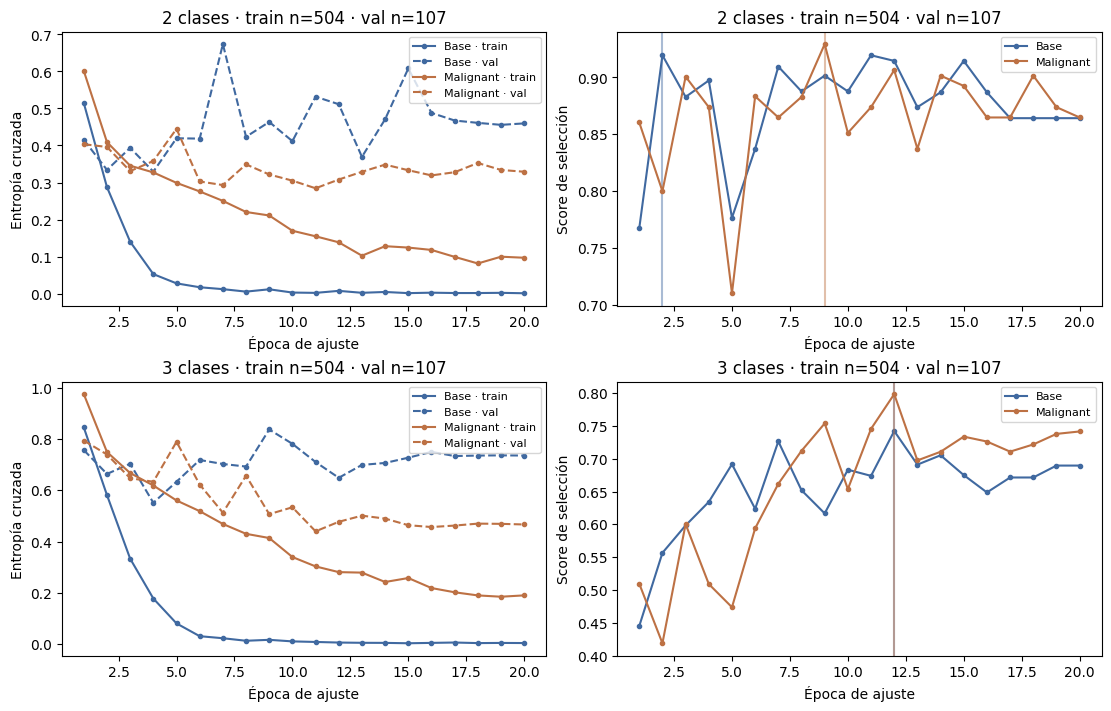

In [8]:
runs_two = {}
for task in (2, 3):
    for recipe in ("Base", "Malignant"):
        fitted = fit(task, recipe)
        if fitted is None:
            continue
        y_val = VAL[f"y{task}"].to_numpy(dtype=int)
        tau, spec = calibrate(y_val, fitted["val_prob"], task)
        tau2, spec2 = calibrate(VAL.y2.to_numpy(), fitted["val_prob"], 2) if task == 3 else (tau, spec)
        runs_two[task, recipe] = {"hist": fitted["hist"], "epoca": fitted["epoca"], "tau": tau,
                                  "tau2": tau2, "spec": spec, "spec2": spec2,
                                  "prob": evaluate_scenarios(fitted["model"], task)}
        del fitted
if runs_two:
    settings = [{"clases": task, "brazo": arm,
                 **{k: outcome[k] for k in ("epoca", "tau", "tau2", "spec", "spec2")}}
                for (task, arm), outcome in runs_two.items()]
    display(pd.DataFrame(settings).round(3))
    fig, axes = plt.subplots(2, 2, figsize=(11, 7), layout="constrained")
    for task in (2, 3):
        for color, arm in zip(SOURCE_COLORS, ("Base", "Malignant")):
            if (task, arm) not in runs_two:
                continue
            outcome = runs_two[task, arm]
            hist = outcome["hist"]
            axes[task-2, 0].plot(hist.epoca, hist.train, color=color, marker=".", label=f"{arm} · train")
            axes[task-2, 0].plot(hist.epoca, hist.val, "--", color=color, marker=".", label=f"{arm} · val")
            axes[task-2, 1].plot(hist.epoca, hist.score, color=color, marker=".", label=arm)
            axes[task-2, 1].axvline(outcome["epoca"], color=color, alpha=.45)
        for ax, ylabel in zip(axes[task-2], ("Entropía cruzada", "Score de selección")):
            ax.set(title=f"{task} clases · train n={len(TRAIN)} · val n={len(VAL)}", xlabel="Época de ajuste", ylabel=ylabel)
            if ax.lines:
                ax.legend(fontsize=8)
    plt.show()

La pérdida de entrenamiento se calcula con la transformación del brazo y la de validación siempre usa el mismo preprocesamiento Base. El score describe la selección de época dentro de cada tarea. Las diferencias tras una época solo verifican el piloto.

### Matrices y efecto del aumento

Se comparan los brazos sobre imágenes pareadas de la partición auditada. Se muestran dos lecturas para los modelos de tres clases. Se presenta la estadificación en Moondream y la detección binaria en las fuentes con etiquetas válidas. Los demás resultados de estadio se omiten por nivel de las referencias. El análisis de errores registra FN, confusión de estadio y saltos entre extremos.

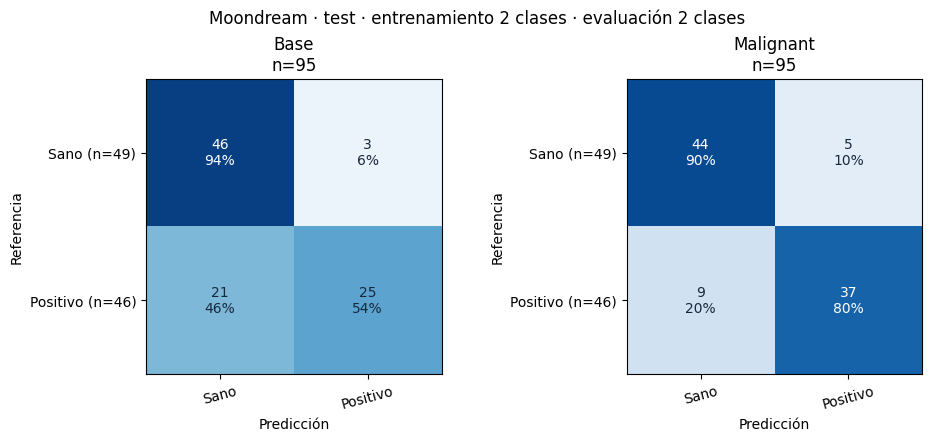

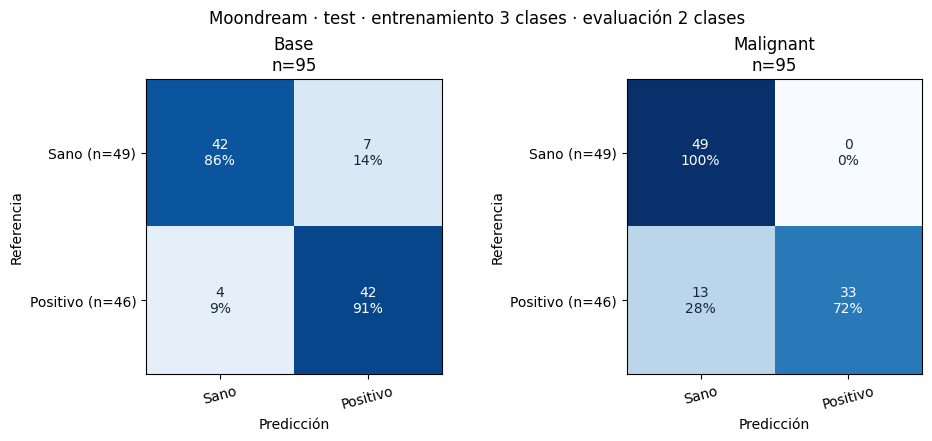

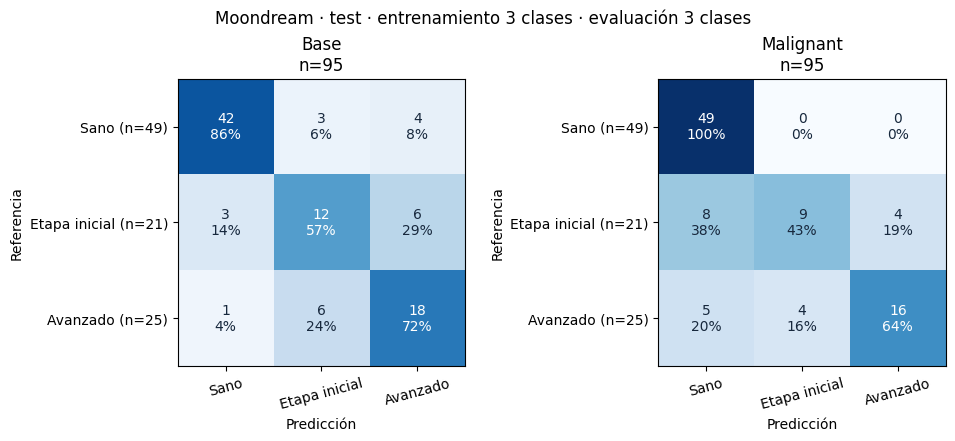

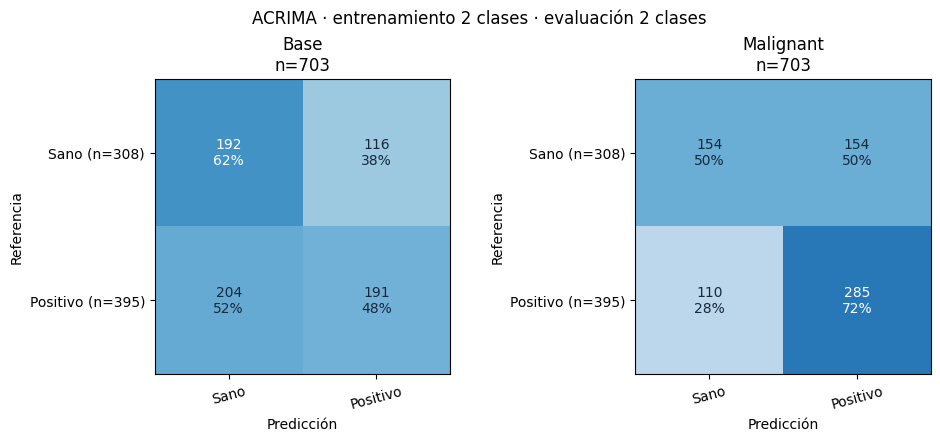

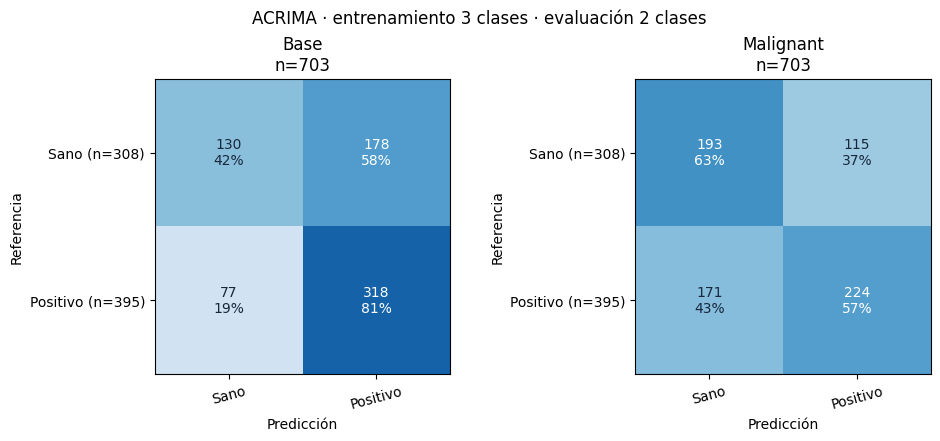

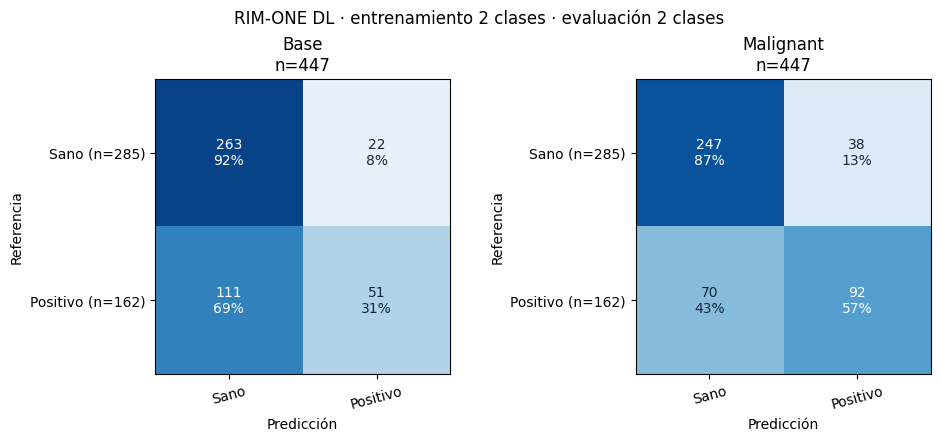

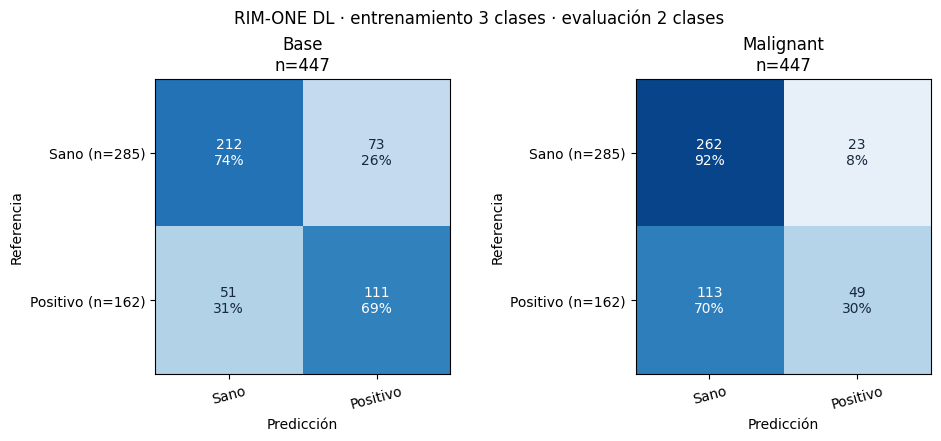

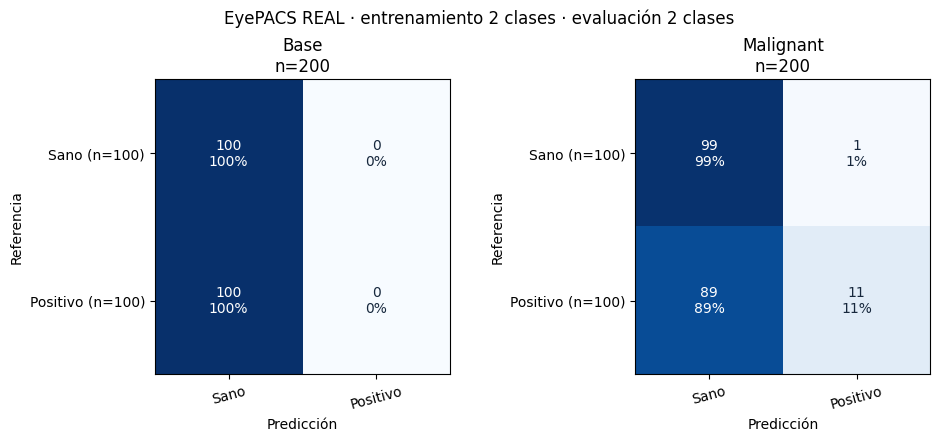

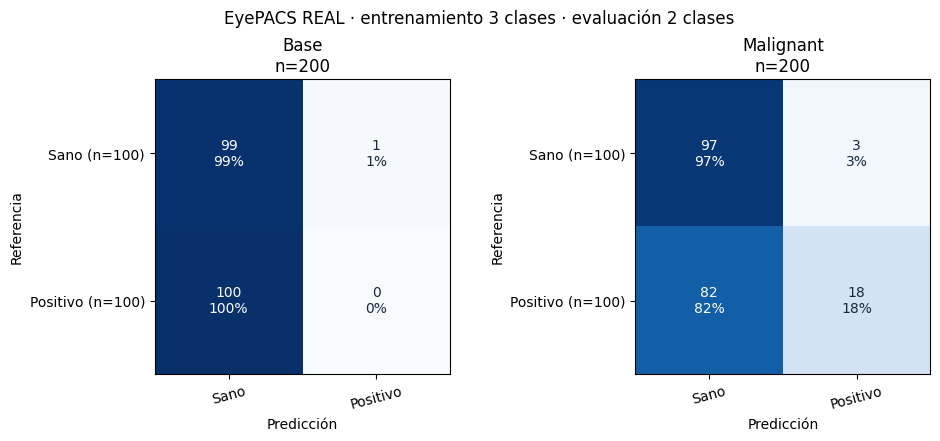

,tarea,nivel,cohorte,brazo,n,F1 macro,exactitud,sensibilidad,especificidad,TFP,...,FN,AUROC,AP,recall inicial,recall avanzado,QWK,errores adyacentes,errores sano ↔ avanzado,FN inicial,FN avanzado
0,2,2,Moondream · test,Base,95,0.734,0.747,0.543,0.939,0.061,...,21.0,0.921,0.896,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,2,Moondream · test,Malignant,95,0.852,0.853,0.804,0.898,0.102,...,9.0,0.944,0.930,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3,2,Moondream · test,Base,95,0.884,0.884,0.913,0.857,0.143,...,4.0,0.948,0.937,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3,2,Moondream · test,Malignant,95,0.859,0.863,0.717,1.000,0.000,...,13.0,0.969,0.968,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,3,3,Moondream · test,Base,95,0.712,0.758,0.913,0.857,0.143,...,NaN,NaN,NaN,0.571,0.72,0.726,18.0,5.0,3.0,1.0
5,3,3,Moondream · test,Malignant,95,0.708,0.779,0.717,1.000,0.000,...,NaN,NaN,NaN,0.429,0.64,0.733,16.0,5.0,8.0,5.0
6,2,2,ACRIMA,Base,703,0.545,0.545,0.484,0.623,0.377,...,204.0,0.593,0.661,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,2,2,ACRIMA,Malignant,703,0.611,0.624,0.722,0.500,0.500,...,110.0,0.657,0.688,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,3,2,ACRIMA,Base,703,0.609,0.637,0.805,0.422,0.578,...,77.0,0.692,0.744,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,3,2,ACRIMA,Malignant,703,0.592,0.593,0.567,0.627,0.373,...,171.0,0.641,0.692,NaN,NaN,NaN,NaN,NaN,NaN,NaN


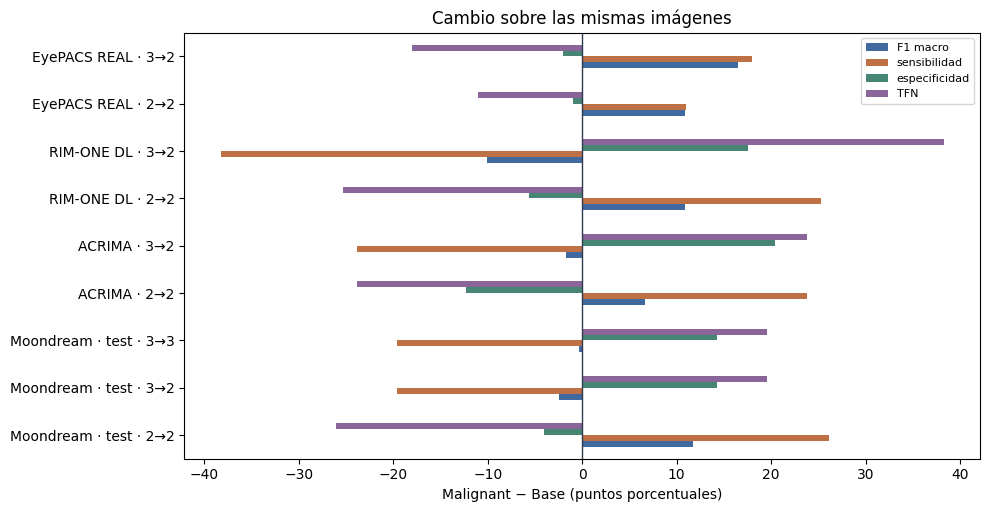

FN  FN inicial  FN avanzado  \
tarea nivel cohorte                                           
2     2     Moondream · test -12.0         NaN          NaN   
3     2     Moondream · test   9.0         NaN          NaN   
      3     Moondream · test   NaN         5.0          4.0   
2     2     ACRIMA           -94.0         NaN          NaN   
3     2     ACRIMA            94.0         NaN          NaN   
2     2     RIM-ONE DL       -41.0         NaN          NaN   
3     2     RIM-ONE DL        62.0         NaN          NaN   
2     2     EyePACS REAL     -11.0         NaN          NaN   
3     2     EyePACS REAL     -18.0         NaN          NaN   

                              errores sano ↔ avanzado  
tarea nivel cohorte                                    
2     2     Moondream · test                      NaN  
3     2     Moondream · test                      NaN  
      3     Moondream · test                      0.0  
2     2     ACRIMA                                NaN  
3     2     ACRIMA                                NaN  
2     2     RIM-ONE DL                            NaN  
3     2     RIM-ONE DL                            NaN  
2     2     EyePACS REAL                          NaN  
3     2     EyePACS REAL                          NaN

,medida,delta,p2.5,p97.5,cohorte,tarea,nivel,n
0,F1 macro,0.117,0.038,0.201,Moondream · test,2,2,95
1,sensibilidad,0.261,0.130,0.391,Moondream · test,2,2,95
2,especificidad,-0.041,-0.122,0.041,Moondream · test,2,2,95
3,F1 macro,-0.025,-0.104,0.053,Moondream · test,3,2,95
4,sensibilidad,-0.196,-0.326,-0.087,Moondream · test,3,2,95
5,especificidad,0.143,0.061,0.245,Moondream · test,3,2,95
6,F1 macro,-0.004,-0.109,0.095,Moondream · test,3,3,95
7,sensibilidad,-0.196,-0.326,-0.087,Moondream · test,3,3,95
8,especificidad,0.143,0.061,0.245,Moondream · test,3,3,95
9,F1 macro,0.066,0.034,0.101,ACRIMA,2,2,703


In [9]:
def evaluate_arms(task, level, source, rows):
    labels = CLASSES if level == 3 else BINARY
    y = rows[f"y{level}"].to_numpy(dtype=int)
    records, panel, predictions = [], {}, {}
    for arm in ("Base", "Malignant"):
        outcome = runs_two.get((task, arm))
        if outcome is None:
            continue
        prob = outcome["prob"][source]
        if level == 3:
            pred = decide(prob, outcome["tau"])
            stats, cm = metrics(y, pred, 3)
        else:
            score = p_positive(prob)
            pred = (score >= outcome["tau2"]).astype(int)
            stats, cm = summarize_binary(y, pred, score)
        records.append({"tarea": task, "nivel": level, "cohorte": source, "brazo": arm, **stats})
        panel[arm], predictions[arm] = cm, pred
    if not panel:
        return [], pd.DataFrame()
    title = f"{source} · entrenamiento {task} clases · evaluación {level} clases"
    matrices(panel, labels, title)
    if len(panel) == 2:
        intervals = paired_delta(rows, y, predictions["Base"], predictions["Malignant"], level)
        return records, intervals.assign(cohorte=source, tarea=task, nivel=level, n=len(rows))
    return records, pd.DataFrame()

all_records, all_intervals = [], []
for source, rows in EVAL_SETS.items():
    cases = [(2, 2), (3, 2)]
    if source == INTERNAL:
        cases.append((3, 3))
    for task, level in cases:
        records, intervals_two = evaluate_arms(task, level, source, rows)
        all_records.extend(records)
        if len(intervals_two):
            all_intervals.append(intervals_two)
if all_records:
    two = pd.DataFrame(all_records)
    two.to_csv(RUN / "02_metricas_factorial.csv", index=False)
    display(two.round(3))
    keys = ["tarea", "nivel", "cohorte"]
    base = two.loc[two.brazo.eq("Base")].set_index(keys)
    augmentation = two.loc[two.brazo.eq("Malignant")].set_index(keys)
    cols = ["F1 macro", "sensibilidad", "especificidad", "TFN"]
    delta = augmentation[cols].subtract(base[cols]).dropna(how="all")
    if len(delta):
        delta.index = [f"{s} · {t}→{l}" for t, l, s in delta.index]
        ax = (100 * delta).plot.barh(figsize=(10, max(5, .58 * len(delta))), color=SOURCE_COLORS[:len(cols)])
        ax.axvline(0, color="#2e3a4f", lw=1)
        ax.set(xlabel="Malignant − Base (puntos porcentuales)", title="Cambio sobre las mismas imágenes")
        ax.legend(fontsize=8)
        plt.tight_layout()
        plt.show()
    errors = ["FN", "FN inicial", "FN avanzado", "errores sano ↔ avanzado"]
    display((augmentation[errors].subtract(base[errors])).round(1))
if all_intervals:
    display(pd.concat(all_intervals, ignore_index=True).round(3))

Cada par de matrices mantiene filas reales y los mismos soportes. Las barras muestran Malignant menos Base. Una diferencia positiva en TFN indica más positivos omitidos. Los intervalos pareados resumen variación del test bajo el agrupamiento disponible. El test usa las imágenes originales de evaluación con resize y normalización.

## Interpretación y limitaciones

Se resume el cambio en F1 macro y TFN para cada tarea, tipo de referencia y cohorte. Un brazo puede mejorar su discriminación y mostrar un intercambio distinto de sensibilidad y especificidad al calibrar su umbral. El efecto estimado combina escala, encuadre, fondo, fotometría y espejos de la receta completa. La contribución de cada componente y la variabilidad entre semillas requieren diseños adicionales.

In [10]:
if all_records and len(delta):
    for (task, level, cohort), group in two.groupby(keys, sort=False):
        row = group.set_index("brazo")
        if {"Base", "Malignant"}.issubset(row.index):
            change = row.loc["Malignant", cols] - row.loc["Base", cols]
            print(f"{cohort} · {task}→{level} (n={int(row.iloc[0].n)}): "
                  f"Δ F1 macro {100 * change['F1 macro']:+.1f} pp; Δ TFN {100 * change.TFN:+.1f} pp.")
    if PILOT:
        print("Piloto: las curvas corresponden a una época de ajuste. El resultado cuantifica la corrida de comprobación.")

Moondream · test · 2→2 (n=95): Δ F1 macro +11.7 pp; Δ TFN -26.1 pp.
Moondream · test · 3→2 (n=95): Δ F1 macro -2.5 pp; Δ TFN +19.6 pp.
Moondream · test · 3→3 (n=95): Δ F1 macro -0.4 pp; Δ TFN +19.6 pp.
ACRIMA · 2→2 (n=703): Δ F1 macro +6.6 pp; Δ TFN -23.8 pp.
ACRIMA · 3→2 (n=703): Δ F1 macro -1.7 pp; Δ TFN +23.8 pp.
RIM-ONE DL · 2→2 (n=447): Δ F1 macro +10.9 pp; Δ TFN -25.3 pp.
RIM-ONE DL · 3→2 (n=447): Δ F1 macro -10.1 pp; Δ TFN +38.3 pp.
EyePACS REAL · 2→2 (n=200): Δ F1 macro +10.9 pp; Δ TFN -11.0 pp.
EyePACS REAL · 3→2 (n=200): Δ F1 macro +16.5 pp; Δ TFN -18.0 pp.


En Moondream (n=95), Malignant cambió el F1 macro en **+11,7 pp** para detección con cabeza binaria y **-0,4 pp** para estadificar. En esas evaluaciones, la TFN cambió -26,1 pp y +19,6 pp, respectivamente.

En Moondream Staged (n=150 originales), la distancia entre las medianas de clase más separadas para azul medio pasó de 34,3 a 25,8 niveles con Malignant en la muestra visual.

En EyePACS REAL (n=100 originales), la distancia entre las medianas de clase más separadas para fondo casi negro pasó de 0,3 a 0,4 puntos porcentuales con Malignant en la muestra visual.